<a href="https://colab.research.google.com/github/sana-sadiq-astro/wasp18b-tess-light-curve/blob/main/WASP_18b_TESS_transit_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Measuring the orbit and size of the exoplanet WASP-18 b from TESS data

**Author:** Sana Sadiq

**Goal:** Recover the orbital period, transit depth and planet radius of WASP-18 b from public TESS light curves, and compare with published values.

**Data:** NASA TESS, target TIC 100100827 (WASP-18), SPOC 2-minute cadence, Sector 2 (main analysis) and Sector 3 (independent check), accessed with the Lightkurve package.

**Method:** (1) download and normalize the light curve, (2) remove slow trends with a flattening filter, (3) search for repeating dips with a Box Least Squares (BLS) periodogram, (4) fold the data on the best period, (5) convert depth to planet radius.

SearchResult containing 10 data products.

 #      mission     year author exptime target_name distance
                                   s                 arcsec 
--- --------------- ---- ------ ------- ----------- --------
  0  TESS Sector 02 2018   SPOC     120   100100827      0.0
  1  TESS Sector 03 2018   SPOC     120   100100827      0.0
  2  TESS Sector 29 2020   SPOC     120   100100827      0.0
  3  TESS Sector 30 2020   SPOC     120   100100827      0.0
  4  TESS Sector 69 2023   SPOC     120   100100827      0.0
  5  TESS Sector 96 2025   SPOC     120   100100827      0.0
  6 TESS Sector 103 2026   SPOC     120   100100827      0.0
  7 TESS Sector 104 2026   SPOC     120   100100827      0.0
  8 TESS Sector 105 2026   SPOC     120   100100827      0.0
  9 TESS Sector 106 2026   SPOC     120   100100827      0.0


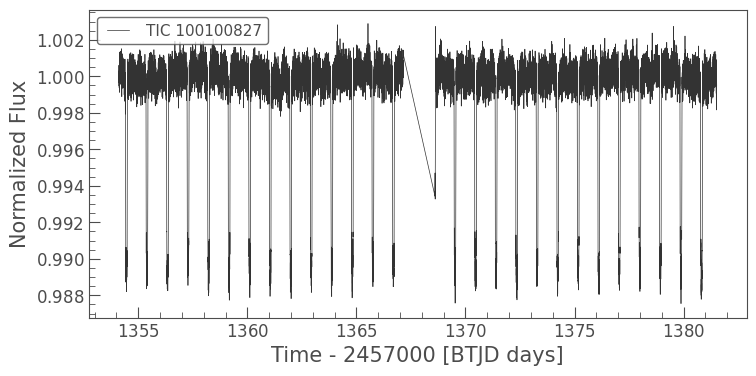

In [ ]:
!pip install lightkurve -q
import numpy as np, lightkurve as lk
res = lk.search_lightcurve("WASP-18", mission="TESS", author="SPOC", exptime=120)
print(res)
lc = res[0].download().remove_nans().normalize()
lc.plot();

How often they meet (days): 0.9415441544154415 d
How dim the star gets: 0.00948397806746096
How long each meeting lasts (hours): 1.92


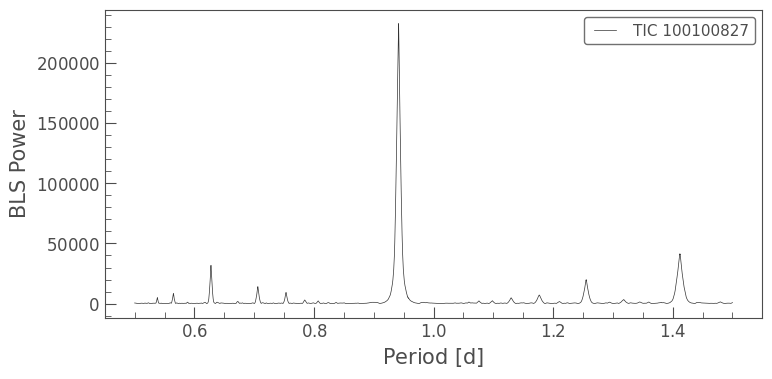

In [ ]:
flat = lc.flatten(window_length=1001)
bls = flat.to_periodogram("bls", period=np.linspace(0.5, 1.5, 10000), duration=[0.05, 0.08, 0.1])
bls.plot();
P = bls.period_at_max_power
depth = float(np.asarray(bls.depth_at_max_power))
dur = bls.duration_at_max_power
print("How often they meet (days):", P)
print("How dim the star gets:", depth)
print("How long each meeting lasts (hours):", dur.value * 24)

In [ ]:
lc2 = res[1].download().remove_nans().normalize()
flat2 = lc2.flatten(window_length=1001)
bls2 = flat2.to_periodogram("bls", period=np.linspace(0.5, 1.5, 10000), duration=[0.05, 0.08, 0.1])
print("Sector 3 period:", bls2.period_at_max_power)
print("Sector 3 depth:", float(np.asarray(bls2.depth_at_max_power)))

Sector 3 period: 0.9412441244124412 d
Sector 3 depth: 0.009627724474703267


(-0.2, 0.2)

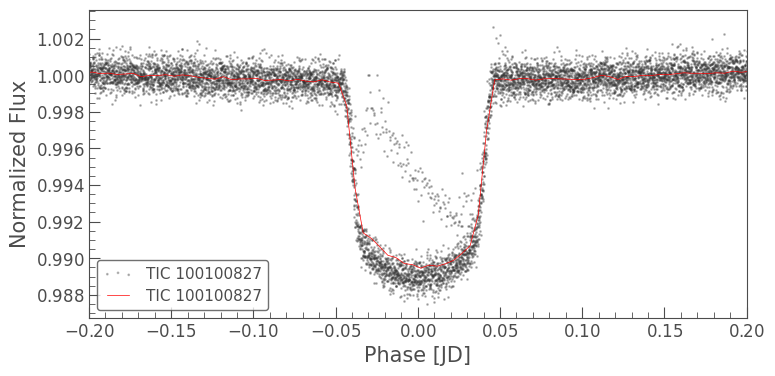

In [ ]:
folded = flat.fold(period=P, epoch_time=bls.transit_time_at_max_power)
ax = folded.scatter(alpha=0.3)
folded.bin(time_bin_size=0.005).plot(ax=ax, c="r")
ax.set_xlim(-0.2, 0.2)

In [ ]:
rp_rs = np.sqrt(depth)
print("Planet radius (Jupiter radii):", rp_rs * 1.2561 * 9.73)

Planet radius (Jupiter radii): 1.190233929512566


## Results

| | This analysis | Published (NASA Exoplanet Archive) |
|---|---|---|
| Orbital period | 0.9415 d (Sector 2), 0.9412 d (Sector 3) | 0.94145 d |
| Transit depth | about 0.95% (Sector 2), 0.96% (Sector 3) | n/a |
| Planet radius | about 1.19 Jupiter radii | 1.24 ± 0.08 Jupiter radii |

The two sectors agree, and my radius is within the published uncertainty. The stellar radius used (1.2561 solar radii) is from the NASA Exoplanet Archive.

## Limitations
- BLS duration was tested on a coarse grid, so the duration is a rough estimate.
- I did not fit a full transit model, so the radius ignores limb darkening.
- The main analysis uses one sector; Sector 3 is an independent check.

## What I learned (in my own words)
- Flattening: There are many slow drifts, but flattening is the thing that removes that slow dips and only keep or measure the quick dip of the planet, which is of course of the planet passing in front of the star. That quick dip lasts for approximately 2 hours.
- BLS: BLS tries many possible gaps between dips, and the tall spike marks the gap that fits best, the orbital period of about 0.94 days. It means that tall spike shows us how often the orbit period happens.
- Folding: Folding stacks every orbit on top of each other, so the planet's dip lines up in the same spot and the random noise averages out.
- Depth to size: The depth (0.0095) is the fraction of the star's area the planet covers, so its square root (0.097) gives the planet's radius compared with the star's. Multiplying by the star's radius from the NASA archive gives about 1.19 Jupiter radii.